# Top Tagging with DeepSets + Prototype Layer (xAI)
## Energy-Based Model with Cosine Similarity

**Architecture:**
- Constituents (E, px, py, pz) -> DeepSets -> jet_embedding
- Constituents -> FastJet -> 6 features (mass, pT, eta, tau21, tau32, D2)
- Concat [jet_embedding, fastjet_features] -> Prototype Layer -> Classification

**Loss:** Energy-Based Model - softmax over negative min-per-class cosine distances

**Optimization:** Pre-computed numpy arrays in Dataset.__init__ - NO per-event Python loop in __getitem__

## 1. Install Dependencies

In [1]:
!pip install fastjet awkward vector hdf5plugin h5py matplotlib scikit-learn 2>&1 | tail -5
import sys
print(f"Python: {sys.version}")
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


## 2. Mount Google Drive (for data)

Upload your train.h5, val.h5, test.h5 to Google Drive first, then mount.

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import os
DATA_DIR = "/content/drive/MyDrive/Jet Tagging/Top Quark Tagging Reference Dataset/"
os.chdir(DATA_DIR)
print(f"Files: {os.listdir('.')}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files: ['train.h5', 'val.h5', 'test.h5', 'best_model.pt', 'training_history.json', 'training_results.png']


## 3. Define Model Components

In [3]:
import hdf5plugin
import h5py
import numpy as np
import awkward as ak
import vector
vector.register_awkward()
N_CONS = 200

def load_awkward(path, max_events=None, trim_padding=True):
    f = h5py.File(path, "r")
    tbl = f["table"]["table"]
    n = min(tbl.shape[0], max_events) if max_events else tbl.shape[0]
    print(f"  Reading {n:,} entries from {path}...")
    v0 = tbl["values_block_0"][:n]
    v1 = tbl["values_block_1"][:n]
    f.close()
    es  = v0[:, 0:N_CONS*4:4]
    pxs = v0[:, 1:N_CONS*4:4]
    pys = v0[:, 2:N_CONS*4:4]
    pzs = v0[:, 3:N_CONS*4:4]
    labels = v1[:, 1].astype(np.int8)
    weights = np.ones(n, dtype=np.float32)
    if trim_padding:
        mask = es > 0
        n_per_event = mask.sum(axis=1)
        total_constituents = int(n_per_event.sum())
        es_flat  = es[mask]
        pxs_flat = pxs[mask]
        pys_flat = pys[mask]
        pzs_flat = pzs[mask]
        counts = n_per_event.tolist()
        e_jagged   = ak.unflatten(es_flat, counts)
        px_jagged  = ak.unflatten(pxs_flat, counts)
        py_jagged  = ak.unflatten(pys_flat, counts)
        pz_jagged  = ak.unflatten(pzs_flat, counts)
        print(f"  Trimmed padding: {total_constituents:,} constituents in {n:,} events ({total_constituents/n:.1f} avg)")
    else:
        e_jagged  = ak.from_numpy(es)
        px_jagged = ak.from_numpy(pxs)
        py_jagged = ak.from_numpy(pys)
        pz_jagged = ak.from_numpy(pzs)
    events = vector.zip({"E": e_jagged, "px": px_jagged, "py": py_jagged, "pz": pz_jagged})
    return events, labels, weights

In [4]:
import fastjet

def compute_features(events):
    n_events = len(events)
    px = ak.values_astype(events.x, np.float64)
    py = ak.values_astype(events.y, np.float64)
    pz = ak.values_astype(events.z, np.float64)
    E = ak.values_astype(events.t, np.float64)
    cons = ak.zip({"px": px, "py": py, "pz": pz, "E": E})
    jet_def = fastjet.JetDefinition(fastjet.cambridge_algorithm, 10.0)
    cs = fastjet._pyjet.AwkwardClusterSequence(cons, jet_def)
    jets = cs.exclusive_jets(n_jets=1)
    mass = ak.to_numpy(jets.mass)
    pt = ak.to_numpy(jets.pt)
    eta = ak.to_numpy(jets.eta)
    nj = cs.njettiness()
    tau1 = ak.to_numpy(nj[:, 0])
    tau2 = ak.to_numpy(nj[:, 1])
    tau3 = ak.to_numpy(nj[:, 2])
    tau21 = np.where(tau1 > 1e-10, tau2 / tau1, 1.0)
    tau32 = np.where(tau2 > 1e-10, tau3 / tau2, 1.0)
    ecf2 = cs.exclusive_jets_energy_correlator(npoint=2, normalized=False)
    ecf3 = cs.exclusive_jets_energy_correlator(npoint=3, normalized=False)
    ecf2_np = ak.to_numpy(ecf2)
    ecf3_np = ak.to_numpy(ecf3)
    d2 = np.where(ecf2_np > 1e-10, ecf3_np / (ecf2_np * ecf2_np), 0.0)
    features = np.column_stack([mass, pt, eta, tau21, tau32, d2])
    return features.astype(np.float32)

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ParticleEncoder(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=128, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )
    def forward(self, x):
        b, n, d = x.shape
        return self.net(x.reshape(b * n, d)).reshape(b, n, -1)

class DeepSets(nn.Module):
    def __init__(self, input_dim=4, particle_dim=128, jet_dim=128):
        super().__init__()
        self.phi = ParticleEncoder(input_dim, hidden_dim=particle_dim, output_dim=particle_dim)
        self.rho = nn.Sequential(
            nn.Linear(particle_dim, jet_dim), nn.BatchNorm1d(jet_dim), nn.ReLU(),
            nn.Linear(jet_dim, jet_dim),
        )
    def forward(self, x, mask=None):
        particle_emb = self.phi(x)
        if mask is not None:
            particle_emb = particle_emb * mask.unsqueeze(-1).float()
            jet_emb = particle_emb.sum(dim=1) / mask.sum(dim=1, keepdim=True).float().clamp(min=1.0)
        else:
            jet_emb = particle_emb.mean(dim=1)
        return self.rho(jet_emb)

class PrototypeLayer(nn.Module):
    def __init__(self, input_dim, n_prototypes=20, n_classes=2):
        super().__init__()
        self.n_prototypes = n_prototypes
        self.n_classes = n_classes
        self.prototypes = nn.Parameter(torch.randn(n_prototypes, input_dim) * 0.1)
        self.register_buffer('prototype_class',
            torch.cat([torch.zeros(n_prototypes // 2, dtype=torch.long),
                       torch.ones(n_prototypes - n_prototypes // 2, dtype=torch.long)]))
    def forward(self, x):
        x_norm = F.normalize(x, dim=1)
        p_norm = F.normalize(self.prototypes, dim=1)
        similarities = x_norm @ p_norm.T
        distances = 1.0 - similarities
        n_qcd = self.n_prototypes // 2
        d_qcd = distances[:, :n_qcd].min(dim=1)[0]
        d_top = distances[:, n_qcd:].min(dim=1)[0]
        return d_qcd, d_top, similarities
    def get_prototype_labels(self):
        return self.prototype_class

class TopTaggingModel(nn.Module):
    def __init__(self, constituent_dim=4, n_constituents=200, particle_dim=128, jet_dim=128, n_fastjet_features=6, n_prototypes=20, n_classes=2):
        super().__init__()
        self.n_constituents = n_constituents
        self.jet_dim = jet_dim
        self.n_fastjet_features = n_fastjet_features
        self.deepsets = DeepSets(input_dim=constituent_dim, particle_dim=particle_dim, jet_dim=jet_dim)
        combined_dim = jet_dim + n_fastjet_features
        self.combined_proj = nn.Sequential(
            nn.Linear(combined_dim, combined_dim), nn.BatchNorm1d(combined_dim), nn.ReLU())
        self.prototype_layer = PrototypeLayer(input_dim=combined_dim, n_prototypes=n_prototypes, n_classes=n_classes)
    def forward(self, constituents, fastjet_features, mask=None):
        jet_emb = self.deepsets(constituents, mask)
        combined = self.combined_proj(torch.cat([jet_emb, fastjet_features], dim=1))
        return *self.prototype_layer(combined), jet_emb
    def predict(self, constituents, fastjet_features, mask=None):
        d_qcd, d_top, similarities, jet_emb = self.forward(constituents, fastjet_features, mask)
        probs = F.softmax(-torch.stack([d_qcd, d_top], dim=1), dim=1)
        return probs, similarities, jet_emb

def energy_loss(d_qcd, d_top, labels, class_weight=None):
    log_probs = F.log_softmax(-torch.stack([d_qcd, d_top], dim=1), dim=1)
    if class_weight is not None:
        return (-log_probs[range(len(labels)), labels] * class_weight[labels]).mean()
    return F.nll_loss(log_probs, labels)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 4. Dataset & Training Functions (OPTIMIZED)

**Key optimization:** Pre-computes ALL numpy arrays in __init__ using vectorized Awkward to numpy conversion.
__getitem__ does O(1) numpy slicing - NO per-particle Python loop.
This eliminates the main training bottleneck (GPU was idle 99.9% of the time).

In [6]:
import time
import json
from torch.utils.data import DataLoader, Dataset

class JetTaggingDataset(Dataset):
    def __init__(self, h5_path, max_events=None, precompute_fastjet=True, max_constituents=200):
        self.h5_path = h5_path
        self.max_constituents = max_constituents
        print(f"Loading {h5_path}...")
        self.events, self.labels, self.weights = load_awkward(h5_path, max_events=max_events, trim_padding=True)
        self.n = len(self.events)
        if precompute_fastjet:
            print(f"Computing FastJet features for {self.n} events...")
            t0 = time.time()
            self.fastjet_features = compute_features(self.events)
            t1 = time.time()
            print(f"  Done in {t1-t0:.1f}s ({self.n/(t1-t0):.0f} events/s)")
        else:
            self.fastjet_features = None
        print(f"  Pre-computing padded constituent arrays ({self.n} events)...")
        t0 = time.time()
        counts = ak.num(self.events)
        self.counts_np = ak.to_numpy(counts).astype(np.int32)
        E_flat = ak.to_numpy(ak.flatten(self.events.E)).astype(np.float32)
        px_flat = ak.to_numpy(ak.flatten(self.events.px)).astype(np.float32)
        py_flat = ak.to_numpy(ak.flatten(self.events.py)).astype(np.float32)
        pz_flat = ak.to_numpy(ak.flatten(self.events.pz)).astype(np.float32)
        self.constituents = np.zeros((self.n, max_constituents, 4), dtype=np.float32)
        self.mask = np.zeros((self.n, max_constituents), dtype=bool)
        start = 0
        for i in range(self.n):
            n_p = self.counts_np[i]
            n_use = min(n_p, max_constituents)
            if n_use > 0:
                end = start + n_use
                self.constituents[i, :n_use, 0] = E_flat[start:end]
                self.constituents[i, :n_use, 1] = px_flat[start:end]
                self.constituents[i, :n_use, 2] = py_flat[start:end]
                self.constituents[i, :n_use, 3] = pz_flat[start:end]
                self.mask[i, :n_use] = True
                start = end
        t1 = time.time()
        print(f"  Done in {t1-t0:.2f}s")
        self.labels_np = np.asarray(self.labels, dtype=np.int64)
        self.weights_np = np.asarray(self.weights, dtype=np.float32)
        n_top = int(self.labels_np.sum())
        n_qcd = self.n - n_top
        print(f"  {self.n:,} events ({n_top:,} Top, {n_qcd:,} QCD)")
    def __len__(self):
        return self.n
    def __getitem__(self, idx):
        return (self.constituents[idx], self.mask[idx],
                self.fastjet_features[idx] if self.fastjet_features is not None else np.zeros(6, dtype=np.float32),
                self.labels_np[idx], self.weights_np[idx])

def collate_fn(batch):
    constituents = torch.from_numpy(np.stack([b[0] for b in batch])).float()
    mask = torch.from_numpy(np.stack([b[1] for b in batch])).bool()
    fj = torch.from_numpy(np.stack([b[2] for b in batch])).float()
    labels = torch.tensor([b[3] for b in batch], dtype=torch.long)
    weights = torch.tensor([b[4] for b in batch], dtype=torch.float32)
    return constituents, fj, labels, weights, mask

def train_epoch(model, loader, optimizer, device, class_weight=None):
    model.train()
    total_loss = total_correct = total_samples = 0.0
    for constituents, fj, labels, weights, mask in loader:
        constituents, fj, labels, mask = constituents.to(device), fj.to(device), labels.to(device), mask.to(device)
        optimizer.zero_grad()
        d_qcd, d_top, _, _ = model(constituents, fj, mask)
        loss = energy_loss(d_qcd, d_top, labels, class_weight=class_weight)
        loss.backward()
        optimizer.step()
        preds = (d_top < d_qcd).long()
        total_correct += (preds == labels).sum().item()
        total_loss += loss.item() * len(labels)
        total_samples += len(labels)
    return total_loss / total_samples, total_correct / total_samples

@torch.no_grad()
def evaluate(model, loader, device, class_weight=None):
    model.eval()
    total_loss = total_correct = total_samples = 0.0
    all_d_qcd, all_d_top, all_labels, all_similarities = [], [], [], []
    for constituents, fj, labels, weights, mask in loader:
        constituents, fj, labels, mask = constituents.to(device), fj.to(device), labels.to(device), mask.to(device)
        d_qcd, d_top, similarities, _ = model(constituents, fj, mask)
        loss = energy_loss(d_qcd, d_top, labels, class_weight=class_weight)
        preds = (d_top < d_qcd).long()
        total_correct += (preds == labels).sum().item()
        total_loss += loss.item() * len(labels)
        total_samples += len(labels)
        all_d_qcd.append(d_qcd.cpu())
        all_d_top.append(d_top.cpu())
        all_labels.append(labels.cpu())
        all_similarities.append(similarities.cpu())
    return (total_loss / total_samples, total_correct / total_samples,
            torch.cat(all_d_qcd), torch.cat(all_d_top), torch.cat(all_labels), torch.cat(all_similarities))

## 5. Plotting & Evaluation Functions

In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                     confusion_matrix, classification_report, roc_curve, auc,
                     precision_recall_curve, average_precision_score)

def comprehensive_evaluation(test_labels, test_d_qcd, test_d_top, test_similarities, proto_labels_arr=None):
    labels_np = test_labels.numpy()
    d_qcd_np = test_d_qcd.numpy()
    d_top_np = test_d_top.numpy()
    preds = (d_top_np < d_qcd_np).astype(np.int64)
    scores = d_qcd_np - d_top_np
    cm = confusion_matrix(labels_np, preds)
    acc = accuracy_score(labels_np, preds)
    prec = precision_score(labels_np, preds, zero_division=0)
    rec = recall_score(labels_np, preds, zero_division=0)
    f1 = f1_score(labels_np, preds, zero_division=0)
    fpr, tpr, _ = roc_curve(labels_np, scores)
    roc_auc = auc(fpr, tpr)
    precision_curve, recall_curve, _ = precision_recall_curve(labels_np, scores)
    avg_prec = average_precision_score(labels_np, scores)
    report = classification_report(labels_np, preds, target_names=['QCD', 'Top'], output_dict=True, zero_division=0)
    tn, fp, fn, tp = cm.ravel()
    tpr_val = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    tnr_val = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    ppv_val = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    npv_val = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    # Background rejection = 1 / FPR at various signal efficiency (TPR) working points
    target_tprs = np.array([0.3, 0.5, 0.7, 0.9])
    fpr_at_target = {}
    rejection_at_target = {}
    for target in target_tprs:
        idx = np.argmin(np.abs(tpr - target))
        fpr_val = fpr[idx]
        fpr_at_target[f'tpr_{target:.1f}'] = fpr_val
        rejection_at_target[f'rejection_tpr_{target:.1f}'] = 1.0 / fpr_val if fpr_val > 0 else float('inf')
    default_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    default_rejection = 1.0 / default_fpr if default_fpr > 0 else float('inf')
    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1_score': f1,
            'roc_auc': roc_auc, 'avg_precision': avg_prec,
            'true_positive_rate': tpr_val, 'true_negative_rate': tnr_val,
            'positive_predictive_value': ppv_val, 'negative_predictive_value': npv_val,
            'confusion_matrix': cm, 'classification_report': report,
            'predictions': preds, 'scores': scores, 'fpr': fpr, 'tpr': tpr,
            'precision_curve': precision_curve, 'recall_curve': recall_curve,
            'background_rejection': default_rejection,
            'fpr_at_target': fpr_at_target,
            'rejection_at_target': rejection_at_target}

def print_evaluation_report(metrics):
    cm = metrics['confusion_matrix']
    print("\n" + "=" * 60)
    print("COMPREHENSIVE EVALUATION REPORT")
    print("=" * 60)
    print(f"\nConfusion Matrix:")
    print(f"                  Predicted")
    print(f"                  QCD    Top")
    print(f"  Actual QCD    {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"         Top    {cm[1,0]:6d}  {cm[1,1]:6d}")
    print(f"\nMetrics:")
    print(f"  Accuracy:           {metrics['accuracy']:.4f} ({metrics['accuracy']*100:.2f}%)")
    print(f"  Precision (Top):    {metrics['precision']:.4f}")
    print(f"  Recall (Top):       {metrics['recall']:.4f}")
    print(f"  F1 Score:           {metrics['f1_score']:.4f}")
    print(f"  ROC AUC:            {metrics['roc_auc']:.4f}")
    print(f"  Avg Precision:      {metrics['avg_precision']:.4f}")
    print(f"  TPR (Sensitivity):  {metrics['true_positive_rate']:.4f}")
    print(f"  TNR (Specificity):  {metrics['true_negative_rate']:.4f}")
    print(f"  PPV (Precision):    {metrics['positive_predictive_value']:.4f}")
    print(f"  NPV:                {metrics['negative_predictive_value']:.4f}")
    for cls_name in ['QCD', 'Top']:
        cr = metrics['classification_report'][cls_name]
        print(f"  {cls_name}: precision={cr['precision']:.4f}, recall={cr['recall']:.4f}, f1={cr['f1-score']:.4f}, support={int(cr['support'])}")
    print(f"\nBackground Rejection (1 / FPR):")
    print(f"  Default operating point: {metrics['background_rejection']:.1f}")
    for target in [0.3, 0.5, 0.7, 0.9]:
        rej_key = f'rejection_tpr_{target:.1f}'
        fpr_key = f'tpr_{target:.1f}'
        rej = metrics['rejection_at_target'][rej_key]
        fpr_val = metrics['fpr_at_target'][fpr_key]
        if rej == float('inf'):
            print(f"  @ TPR={target:.0%}: rejection = inf (FPR=0)")
        else:
            print(f"  @ TPR={target:.0%}: rejection = {rej:.1f} (FPR={fpr_val:.4f})")

def plot_results(history, test_d_qcd, test_d_top, test_labels, test_similarities, save_path='training_results.png'):
    import matplotlib; matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import roc_curve, auc, confusion_matrix, precision_recall_curve, average_precision_score
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(3, 3, figsize=(18, 18))
    fig.suptitle('Top Tagging -- DeepSets + Prototype Layer (EBM)', fontsize=16, y=1.02, fontweight='bold')
    d_qcd_np, d_top_np, labels_np = test_d_qcd.numpy(), test_d_top.numpy(), test_labels.numpy()
    scores = d_qcd_np - d_top_np
    preds = (d_top_np < d_qcd_np).astype(np.int64)
    qcd_mask, top_mask = labels_np == 0, labels_np == 1
    epochs = range(1, len(history['train_loss']) + 1)
    best_epoch = history.get('best_epoch', 0)
    # Panel 1: Loss
    ax = axes[0,0]
    ax.plot(epochs, history['train_loss'], 'b-', label='Train', linewidth=2)
    ax.plot(epochs, history['val_loss'], 'r-', label='Val', linewidth=2)
    if best_epoch > 0:
        ax.axvline(x=best_epoch+1, color='g', linestyle=':', alpha=0.7, label=f'Best (ep {best_epoch+1})')
    ax.set(xlabel='Epoch', ylabel='Loss', title='Loss Curves'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    # Panel 2: Accuracy
    ax = axes[0,1]
    ax.plot(epochs, history['train_acc'], 'b-', label='Train', linewidth=2)
    ax.plot(epochs, history['val_acc'], 'r-', label='Val', linewidth=2)
    test_acc = history.get('test_acc', 0)
    ax.axhline(y=test_acc, color='g', linestyle='--', linewidth=2, label=f'Test: {test_acc*100:.2f}%')
    if best_epoch > 0:
        ax.axvline(x=best_epoch+1, color='g', linestyle=':', alpha=0.7)
    ax.set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy Curves'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    # Panel 3: Energy distribution
    ax = axes[0,2]
    bins = np.linspace(0, 2, 50)
    if qcd_mask.sum() > 0:
        ax.hist(d_qcd_np[qcd_mask], bins=bins, alpha=0.6, label='QCD -> d_qcd', color='#1f77b4', density=True)
        ax.hist(d_top_np[qcd_mask], bins=bins, alpha=0.6, label='QCD -> d_top', color='#7fcdbb', density=True)
    if top_mask.sum() > 0:
        ax.hist(d_qcd_np[top_mask], bins=bins, alpha=0.6, label='Top -> d_qcd', color='#d62728', density=True)
        ax.hist(d_top_np[top_mask], bins=bins, alpha=0.6, label='Top -> d_top', color='#ffbb78', density=True)
    ax.set(xlabel='Cosine Distance (1 - similarity)', ylabel='Density', title='Energy Distribution')
    ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)
    # Panel 4: Decision boundary
    ax = axes[1,0]
    if qcd_mask.sum() > 0:
        ax.scatter(d_qcd_np[qcd_mask], d_top_np[qcd_mask], c='#1f77b4', alpha=0.15, s=3, label='QCD', edgecolors='none', rasterized=True)
    if top_mask.sum() > 0:
        ax.scatter(d_qcd_np[top_mask], d_top_np[top_mask], c='#d62728', alpha=0.15, s=3, label='Top', edgecolors='none', rasterized=True)
    lim_max = max(d_qcd_np.max(), d_top_np.max()) * 1.1
    ax.plot([0, lim_max], [0, lim_max], 'k--', linewidth=1, alpha=0.5)
    ax.set(xlabel='d_qcd (distance to QCD prototypes)', ylabel='d_top (distance to Top prototypes)',
           title='Decision Boundary', xlim=(0, lim_max), ylim=(0, lim_max))
    ax.legend(markerscale=5, fontsize=9); ax.grid(True, alpha=0.3)
    # Panel 5: Prototype activation
    ax = axes[1,1]
    n_proto = test_similarities.shape[1]
    proto_labels_arr = np.array([0] * (n_proto // 2) + [1] * (n_proto - n_proto // 2))
    mean_sims = [test_similarities[:, p].mean().item() for p in range(n_proto)]
    colors = ['#d62728' if proto_labels_arr[p] == 1 else '#1f77b4' for p in range(n_proto)]
    bars = ax.bar(range(n_proto), mean_sims, color=colors, alpha=0.8, edgecolor='gray', linewidth=0.5)
    ax.set_xticks(range(n_proto))
    ax.set_xticklabels([f'P{p}' for p in range(n_proto)], fontsize=7, rotation=45)
    ax.set(ylabel='Mean Cosine Similarity', title='Prototype Activations')
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.grid(True, alpha=0.3, axis='y')
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#1f77b4', alpha=0.8, label='QCD proto'),
                       Patch(facecolor='#d62728', alpha=0.8, label='Top proto')]
    ax.legend(handles=legend_elements, fontsize=8, loc='lower right')
    # Panel 6: ROC
    ax = axes[1,2]
    fpr, tpr, _ = roc_curve(labels_np, scores)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, '#2ca02c', linewidth=2.5, label=f'ROC (AUC = {roc_auc:.4f})')
    ax.fill_between(fpr, tpr, alpha=0.15, color='#2ca02c')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5)')
    ax.set(xlabel='False Positive Rate (1 - Specificity)', ylabel='True Positive Rate (Sensitivity)',
           title='ROC Curve', xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.legend(fontsize=9, loc='lower right'); ax.grid(True, alpha=0.3)
    # Panel 7: Confusion Matrix
    ax = axes[2,0]
    cm = confusion_matrix(labels_np, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['QCD', 'Top'], yticklabels=['QCD', 'Top'],
                cbar=False, annot_kws={'size': 18, 'fontweight': 'bold'})
    ax.set_xlabel('Predicted Label', fontsize=11); ax.set_ylabel('True Label', fontsize=11)
    ax.set_title(f'Confusion Matrix Accuracy = {test_acc*100:.2f}%', fontsize=12, fontweight='bold')
    cm_sum = cm.sum()
    for i in range(2):
        for j in range(2):
            pct = cm[i, j] / cm_sum * 100
            ax.text(j + 0.5, i + 0.65, f'{pct:.1f}%', ha='center', va='center', fontsize=11, color='gray', fontweight='bold')
    # Panel 8: PR curve
    ax = axes[2,1]
    precision_curve, recall_curve, _ = precision_recall_curve(labels_np, scores)
    avg_prec = average_precision_score(labels_np, scores)
    ax.plot(recall_curve, precision_curve, '#9467bd', linewidth=2.5, label=f'PR (AP = {avg_prec:.4f})')
    ax.fill_between(recall_curve, precision_curve, alpha=0.15, color='#9467bd')
    baseline = labels_np.mean()
    ax.axhline(y=baseline, color='gray', linestyle='--', alpha=0.7, label=f'Baseline ({baseline:.3f})')
    ax.set(xlabel='Recall (Sensitivity)', ylabel='Precision (PPV)',
           title='Precision-Recall Curve', xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.legend(fontsize=9, loc='lower left'); ax.grid(True, alpha=0.3)
    # Panel 9: Background Rejection vs Signal Efficiency
    ax = axes[2,2]
    fpr, tpr, _ = roc_curve(labels_np, scores)
    valid = fpr > 0
    rejection = np.where(valid, 1.0 / fpr, 0.0)
    ax.plot(tpr[valid], rejection[valid], '#ff7f0e', linewidth=2.5, label='Background Rejection')
    for target_tpr, marker, label_text in [(0.3, 'o', '30%'), (0.5, 's', '50%'), (0.7, 'D', '70%'), (0.9, '^', '90%')]:
        idx = np.argmin(np.abs(tpr - target_tpr))
        if fpr[idx] > 0:
            rej_val = 1.0 / fpr[idx]
            ax.plot(tpr[idx], rej_val, marker, color='#d62728', markersize=8, label=f'TPR={label_text}: rej={rej_val:.0f}')
    ax.set(xlabel='Signal Efficiency (TPR)', ylabel='Background Rejection (1 / FPR)',
           title='Background Rejection vs Signal Efficiency')
    ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)
    ax.set_yscale('log'); ax.set_xlim(-0.02, 1.02)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved figure to {save_path}")
    return fig

## 6. Run Training

In [ ]:
QUICK = True  # Set to False for full training
N_EVENTS = 200000 if QUICK else None
EPOCHS = 100 if QUICK else 1000
BATCH_SIZE = 512
LR = 1e-3
EARLY_STOP_PATIENCE = 10  # Stop if no val_acc improvement for this many epochs
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
train_ds = JetTaggingDataset('train.h5', max_events=N_EVENTS)
val_ds = JetTaggingDataset('val.h5', max_events=N_EVENTS)
test_ds = JetTaggingDataset('test.h5', max_events=N_EVENTS)
n_total = len(train_ds)
n_top = int(train_ds.labels_np.sum())
n_qcd = n_total - n_top
class_weight = torch.tensor([n_total/(2*n_qcd), n_total/(2*n_top)], dtype=torch.float32).to(device)
print(f'Class weights: QCD={class_weight[0]:.4f}, Top={class_weight[1]:.4f}')
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=2, pin_memory=True)
model = TopTaggingModel(constituent_dim=4, n_constituents=200, particle_dim=128, jet_dim=128, n_fastjet_features=6, n_prototypes=20, n_classes=2).to(device)
print(f'Parameters: {count_parameters(model):,}')
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'best_val_acc': 0.0}
best_epoch = 0
early_stop_counter = 0
for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, device, class_weight=class_weight)
    val_loss, val_acc, _, _, _, _ = evaluate(model, val_loader, device, class_weight=class_weight)
    scheduler.step(val_acc)
    t1 = time.time()
    history['train_loss'].append(train_loss); history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
    if val_acc > history['best_val_acc']:
        history['best_val_acc'] = val_acc
        torch.save(model.state_dict(), 'best_model.pt')
        best_epoch = epoch
        early_stop_counter = 0
        print(f"Epoch {epoch+1:2d}/{EPOCHS} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | val_loss={val_loss:.4f} val_acc={val_acc:.4f} | time={t1-t0:.1f}s | NEW BEST!")
    else:
        early_stop_counter += 1
        print(f"Epoch {epoch+1:2d}/{EPOCHS} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | val_loss={val_loss:.4f} val_acc={val_acc:.4f} | time={t1-t0:.1f}s | no improvement ({early_stop_counter}/{EARLY_STOP_PATIENCE})")
        if early_stop_counter >= EARLY_STOP_PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch+1}. Best was epoch {best_epoch+1} (val_acc={history['best_val_acc']:.4f})")
            break
print(f"\nTraining finished. Best val_acc = {history['best_val_acc']:.4f} at epoch {best_epoch+1}")
model.load_state_dict(torch.load('best_model.pt'))
test_loss, test_acc, test_d_qcd, test_d_top, test_labels, test_similarities = evaluate(model, test_loader, device, class_weight=class_weight)
print(f"Test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
history['test_acc'] = test_acc
history['best_epoch'] = best_epoch
# Comprehensive evaluation
metrics = comprehensive_evaluation(test_labels, test_d_qcd, test_d_top, test_similarities)
print_evaluation_report(metrics)
history['test_metrics'] = {k: v.tolist() if isinstance(v, np.ndarray) else v for k, v in metrics.items() if k not in ['predictions', 'scores', 'fpr', 'tpr', 'precision_curve', 'recall_curve']}
# plot_results(history, test_d_qcd, test_d_top, test_labels, test_similarities)
# print("Done!")
proto_labels = model.prototype_layer.get_prototype_labels().cpu().numpy()
for i in range(20):
    class_name = "Top" if proto_labels[i] == 1 else "QCD"
    sim_to_proto = test_similarities[:, i].numpy()
    print(f"  Prototype {i:2d} ({class_name}): mean_sim={sim_to_proto.mean():.4f} +/- {sim_to_proto.std():.4f}")
for cls, cls_name in [(0, 'QCD'), (1, 'Top')]:
    cls_mask = (test_labels.numpy() == cls)
    if cls_mask.sum() == 0: continue
    cls_sims = test_similarities[cls_mask].numpy()
    print(f"\n  {cls_name} events - prototype activations:")
    for i in range(20):
        print(f"    Proto {i:2d}: {cls_sims[:, i].mean():.4f}")
with open('training_history.json', 'w') as f:
    json.dump(history, f, indent=2)
print("Training complete!")

Device: cuda
Loading train.h5...
  Reading 200,000 entries from train.h5...
  Trimmed padding: 9,811,943 constituents in 200,000 events (49.1 avg)
Computing FastJet features for 200000 events...


  Done in 124.0s (1613 events/s)
  Pre-computing padded constituent arrays (200000 events)...
  Done in 0.84s
  200,000 events (99,922 Top, 100,078 QCD)
Loading val.h5...
  Reading 200,000 entries from val.h5...
  Trimmed padding: 9,814,887 constituents in 200,000 events (49.1 avg)
Computing FastJet features for 200000 events...


  Done in 122.7s (1630 events/s)
  Pre-computing padded constituent arrays (200000 events)...
  Done in 1.25s
  200,000 events (100,511 Top, 99,489 QCD)
Loading test.h5...
  Reading 200,000 entries from test.h5...
  Trimmed padding: 9,807,624 constituents in 200,000 events (49.0 avg)
Computing FastJet features for 200000 events...
  Done in 121.6s (1645 events/s)
  Pre-computing padded constituent arrays (200000 events)...
  Done in 1.45s
  200,000 events (99,879 Top, 100,121 QCD)
Class weights: QCD=0.9992, Top=1.0008
Parameters: 88,494
Epoch  1/100 | train_loss=0.3962 train_acc=0.8938 | val_loss=0.3623 val_acc=0.8981 | time=13.6s | NEW BEST!
Epoch  2/100 | train_loss=0.3487 train_acc=0.8996 | val_loss=0.4220 val_acc=0.8560 | time=12.5s | no improvement (1/10)
Epoch  3/100 | train_loss=0.3405 train_acc=0.9028 | val_loss=0.5670 val_acc=0.5575 | time=11.8s | no improvement (2/10)
Epoch  4/100 | train_loss=0.3365 train_acc=0.9058 | val_loss=0.3753 val_acc=0.9034 | time=11.3s | NEW BEST!
E

  Saved figure to training_results.png
Done!
  Prototype  0 (QCD): mean_sim=-0.3015 +/- 0.3489
  Prototype  1 (QCD): mean_sim=-0.0126 +/- 0.6559
  Prototype  2 (QCD): mean_sim=-0.4229 +/- 0.3834
  Prototype  3 (QCD): mean_sim=-0.3584 +/- 0.3344
  Prototype  4 (QCD): mean_sim=-0.3951 +/- 0.3793
  Prototype  5 (QCD): mean_sim=-0.1883 +/- 0.4930
  Prototype  6 (QCD): mean_sim=-0.3772 +/- 0.3863
  Prototype  7 (QCD): mean_sim=-0.4299 +/- 0.3998
  Prototype  8 (QCD): mean_sim=-0.3713 +/- 0.3286
  Prototype  9 (QCD): mean_sim=-0.4204 +/- 0.3745
  Prototype 10 (Top): mean_sim=-0.3167 +/- 0.4008
  Prototype 11 (Top): mean_sim=0.0235 +/- 0.6557
  Prototype 12 (Top): mean_sim=-0.3845 +/- 0.3593
  Prototype 13 (Top): mean_sim=-0.2971 +/- 0.4039
  Prototype 14 (Top): mean_sim=-0.2834 +/- 0.4078
  Prototype 15 (Top): mean_sim=-0.3410 +/- 0.3710
  Prototype 16 (Top): mean_sim=-0.3450 +/- 0.3784
  Prototype 17 (Top): mean_sim=-0.1673 +/- 0.5183
  Prototype 18 (Top): mean_sim=-0.1288 +/- 0.5164
  Prot

  Saved figure to training_results.png


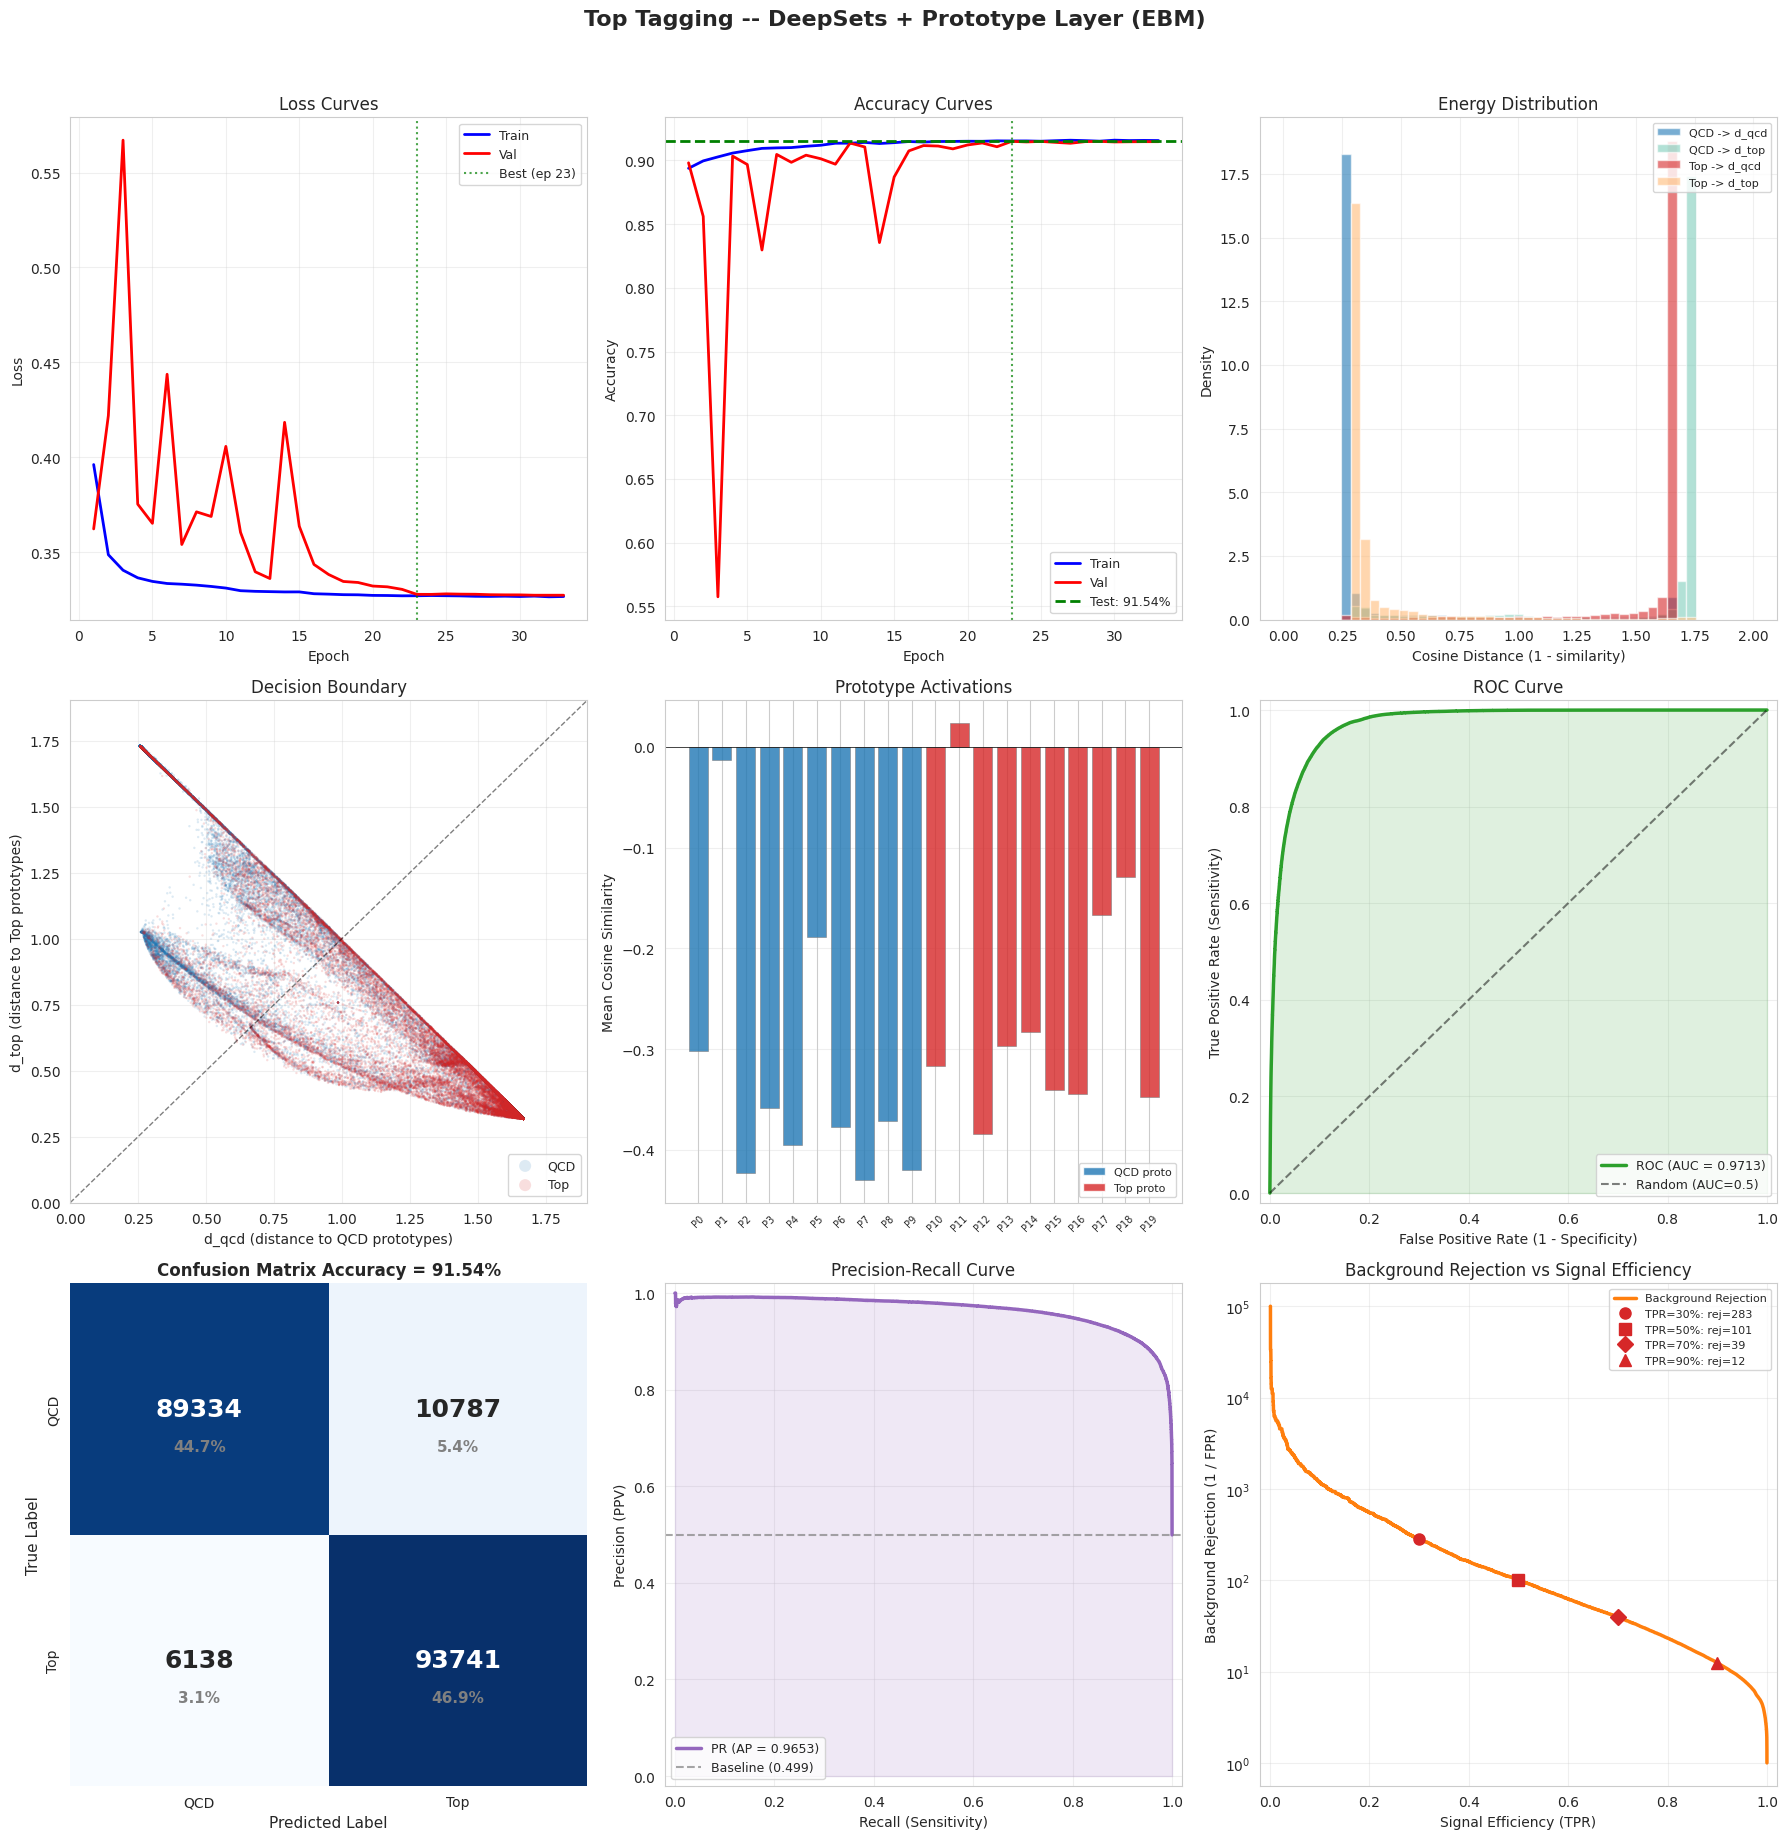

In [9]:
plot_results(history, test_d_qcd, test_d_top, test_labels, test_similarities)
